# 02 · Churn model: out-of-time validation, champion vs challenger, and the retention budget

**Summary.** The production model is reproduced exactly: test AUC 0.7609, validation 0.783, top-decile churn 77.1% and 43.5% of
churners in the riskiest 30%. It then loses its own champion/challenger test. On the untouched Sep 2011 snapshot, a
tuned LightGBM reaches AUC 0.773 (95% CI 0.759-0.786), +0.012 over the champion (paired CI +0.007 to +0.017). A
regularised logistic regression reaches 0.770, +0.009 (CI +0.002 to +0.016). The two challengers cannot be told apart, and
the champion is statistically tied with a 25-cell RFM table. **Recommendation: promote the logistic model**, which is as
accurate and fully transparent. Calibration is the bigger practical problem. Trained on spring snapshots, the model
predicts 64% churn for an autumn base that churns at 50%. Isotonic recalibration on the June snapshot cannot fix a
seasonal shift. An intercept shift to last year's seasonal ratio can, because it is known on the scoring date: the
calibration ratio falls from 1.27 to 1.04 and the Brier score from 0.215 to 0.197. For the budget, *how* customers are
ranked matters far more than *which* model ranks them. At a 10% save rate, 30% margin and £10 per contact, contacting the
top 42% by expected margin at risk nets £15.2K a quarter (90% band £11.6K-£18.5K). The best list ranked by churn risk
nets £5.8K, and the better model adds about £0.4K. The save rate drives the answer (£3.7K at 5%, £102K at 30%), so the
next step is a randomised hold-out to measure it: about 2,000 customers per arm to detect a 10% save rate.

In [1]:
import os, sys, warnings
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "ds" / "dskit").exists())
sys.path.insert(0, str(ROOT / "ds"))
warnings.simplefilter("ignore")              # library warnings print local paths into the outputs
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from dskit import set_style, PALETTE, headline, savefig, audit, eda, evaluate, explain, select, report
import features as F
set_style(); pd.set_option("display.float_format", lambda v: f"{v:,.4f}"); pd.set_option("display.width", 160)
FIG, METRICS, SEED = ROOT / "ds" / "figures", ROOT / "ds" / "reports" / "metrics.json", 42

In [2]:
import json, time
import matplotlib.dates as mdates
import lightgbm as lgb
from IPython.display import display
from threadpoolctl import threadpool_limits
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss, log_loss, roc_auc_score
from sklearn.model_selection import GroupKFold, StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
threadpool_limits(4)                         # HistGradientBoosting would otherwise use every core; other jobs share this machine
T0 = time.perf_counter()

## 1. Design: snapshots and an out-of-time split

A churn score is used on a date to decide who gets a contact, and judged by what happens in the next 90 days. The
validation design copies that. Each **snapshot** date *t* has features from the 365 days before *t* and a label from the
90 days after it. The production ETL trains on the 1 Mar 2011 snapshot, validates on 1 Jun 2011 and, after refitting on
both, scores 1 Sep 2011. That is the test period, untouched until section 5. The labels of the training snapshots end on
29 May and 29 Aug 2011, both before the test date, so no training label comes from the future. A 1 Dec 2010 snapshot is
added only to give model comparison a second out-of-time fold.

In [3]:
lines, _ = F.clean_lines(F.load_raw_lines())
orders = F.build_orders(lines)
DATES = {"cv": "2010-12-01", **F.SNAPSHOTS}
S = {k: F.snapshot(lines, t, orders) for k, t in DATES.items()}
tr, va, te = S["train"], S["valid"], S["test"]
trva = pd.concat([tr, va])
pd.DataFrame({k: {"snapshot": f"{pd.Timestamp(t):%d %b %Y}", "customers": len(S[k]), "churn_rate": round(S[k]["churn"].mean(), 4),
                  "label window ends": f"{pd.Timestamp(t) + pd.Timedelta(days=89):%d %b %Y}"} for k, t in DATES.items()}).T

,snapshot,customers,churn_rate,label window ends
cv,01 Dec 2010,4239,0.6681,28 Feb 2011
train,01 Mar 2011,4260,0.6312,29 May 2011
valid,01 Jun 2011,4324,0.6337,29 Aug 2011
test,01 Sep 2011,4324,0.5046,29 Nov 2011


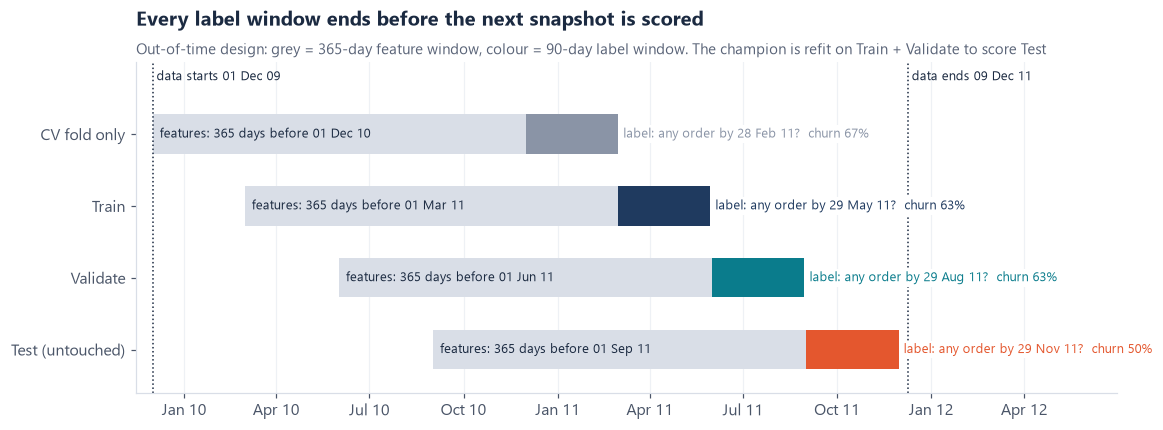

In [4]:
fig, ax = plt.subplots(figsize=(11.5, 3.9))
start, end = lines["Day"].min(), lines["Day"].max()
roles = [("cv", "CV fold only", PALETTE["grey"]), ("train", "Train", PALETTE["navy"]), ("valid", "Validate", PALETTE["teal"]), ("test", "Test (untouched)", PALETTE["coral"])]
for i, (k, _name, c) in enumerate(roles):
    t = pd.Timestamp(DATES[k])
    ax.barh(i, 365, left=mdates.date2num(t - pd.Timedelta(days=365)), color=PALETTE["light"], height=0.55)
    ax.barh(i, 90, left=mdates.date2num(t), color=c, height=0.55)
    ax.text(mdates.date2num(t - pd.Timedelta(days=358)), i, f"features: 365 days before {t:%d %b %y}", va="center", fontsize=8.5, color=PALETTE["ink"])
    ax.text(mdates.date2num(t + pd.Timedelta(days=95)), i, f"label: any order by {t + pd.Timedelta(days=89):%d %b %y}?  churn {S[k]['churn'].mean():.0%}",
            va="center", fontsize=8.5, color=c, bbox=dict(facecolor="white", edgecolor="none", pad=1.5), zorder=5)
for d, lab in ((start, "data starts"), (end, "data ends")):
    ax.axvline(mdates.date2num(d), color=PALETTE["ink"], ls=":", lw=1)
    ax.text(mdates.date2num(d), -0.75, f" {lab} {d:%d %b %y}", fontsize=8.5, color=PALETTE["ink"])
ax.set_yticks(range(len(roles)), [r[1] for r in roles]); ax.invert_yaxis(); ax.set_ylim(len(roles) - 0.4, -1.0)
ax.xaxis_date(); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %y")); ax.grid(axis="y", visible=False)
ax.set_xlim(mdates.date2num(pd.Timestamp("2009-11-15")), mdates.date2num(pd.Timestamp("2012-06-30")))
headline(ax, "Every label window ends before the next snapshot is scored",
         "Out-of-time design: grey = 365-day feature window, colour = 90-day label window. The champion is refit on Train + Validate to score Test")
savefig(fig, "02-design", FIG); plt.show()

## 2. Parity: reproduce the production champion

The Power BI report, README and website quote the ETL's numbers, so the notebook must reproduce them before changing
anything. The champion is the ETL's `HistGradientBoostingClassifier` with the same 13 features and parameters.

In [5]:
pub = json.load(open(ROOT / "ml" / "metrics.json"))
champ_mar = HistGradientBoostingClassifier(**F.HGB_PARAMS).fit(tr[F.FEATS], tr["churn"])
auc_valid = roc_auc_score(va["churn"], champ_mar.predict_proba(va[F.FEATS])[:, 1])
champion = HistGradientBoostingClassifier(**F.HGB_PARAMS).fit(trva[F.FEATS], trva["churn"])
y_te = te["churn"].values
p_champ = champion.predict_proba(te[F.FEATS])[:, 1]
g = evaluate.gains_table(y_te, p_champ)
mine = {"churn_auc_valid": auc_valid, "churn_auc_test": roc_auc_score(y_te, p_champ),
        "churn_auc_recency_only_test": roc_auc_score(y_te, te["recency_days"]), "churn_base_rate_test": y_te.mean(),
        "churn_top_decile_rate": g.loc[1, "rate"], "churn_top30_capture": g.loc[3, "cum_capture"]}
parity = pd.DataFrame({"published": {k: pub[k] for k in mine}, "reproduced": mine})
parity["abs_diff"] = (parity["reproduced"] - parity["published"]).abs()
assert (parity["abs_diff"] <= 0.005).all(), parity
parity

,published,reproduced,abs_diff
churn_auc_valid,0.7830,0.7830,0.0000
churn_auc_test,0.7609,0.7609,0.0000
churn_auc_recency_only_test,0.7080,0.7080,0.0000
churn_base_rate_test,0.5046,0.5046,0.0000
churn_top_decile_rate,0.7714,0.7714,0.0000
churn_top30_capture,0.4354,0.4354,0.0000


In [6]:
etl_country = F.customer_country(lines)               # the ETL's whole-history country (a small look-ahead)
S_etl = {k: F.snapshot(lines, F.SNAPSHOTS[k], orders, country=etl_country) for k in F.SNAPSHOTS}
m_etl = HistGradientBoostingClassifier(**F.HGB_PARAMS).fit(pd.concat([S_etl["train"], S_etl["valid"]])[F.FEATS],
                                                           pd.concat([S_etl["train"], S_etl["valid"]])["churn"])
auc_etl = roc_auc_score(S_etl["test"]["churn"], m_etl.predict_proba(S_etl["test"][F.FEATS])[:, 1])
print(f"Test AUC with the ETL's whole-history country: {auc_etl:.4f}; with history-only country (features.py): {mine['churn_auc_test']:.4f}")

Test AUC with the ETL's whole-history country: 0.7609; with history-only country (features.py): 0.7609


Every published number is reproduced exactly: validation AUC 0.783, test AUC 0.7609, recency-only 0.708, base rate
50.5%, top-decile churn 77.1% and 43.5% of churners in the riskiest 30%. Taking the country from history before *t*
(the leakage-safe version used here) gives the same test AUC to four decimals.

## 3. Leakage screen and drift between training and test

A single feature that almost separates churners from buyers would usually be information from after the snapshot.
Then the population stability index (PSI) of each feature between the training snapshots and the test snapshot.

In [7]:
audit.leakage_screen(tr, F.FEATS, "churn")

,single_feature_auc,direction,review
feature,,,
orders_365,0.7666,-,
orders_all,0.7590,-,
spend_365,0.7579,-,
recency_days,0.7138,+,
products_365,0.7062,-,
spend_90,0.7009,-,
orders_90,0.7003,-,
spend_prev_90,0.6951,-,
avg_gap_days,0.6851,+,


No feature comes near the 0.85 flag. The strongest single feature, orders in the last 12 months, reaches 0.77, so the
model has to combine weak signals. Every feature is computed strictly before the snapshot date
(tests/test_features.py).

In [8]:
psi = eda.stability(trva, te, F.FEATS)
psi.T

feature,tenure_days,recency_days,avg_gap_days,spend_prev_90,orders_all,spend_90,orders_90,products_365,spend_365,cancel_lines_365,orders_365,avg_basket,is_uk
psi,0.7202,0.2241,0.0377,0.0279,0.0257,0.0045,0.0030,0.0028,0.0021,0.0012,0.0011,0.0008,0.0004
status,shifted,monitor,stable,stable,stable,stable,stable,stable,stable,stable,stable,stable,stable


Tenure is flagged as shifted (PSI 0.72), but that is an artefact of the data, not of customers: tenure is counted from the
first order *in the data* (Dec 2009), so the longest possible tenure grows from 455 days at the Mar snapshot to 639 days at
Sep. The test snapshot holds tenures the model never saw. Recency (0.22) moves with the season. Capping tenure at 365
days removes the artefact; the next cell checks what it is worth.

In [9]:
cap = lambda d: d.assign(tenure_days=d["tenure_days"].clip(upper=365))
v_cap = roc_auc_score(va["churn"], HistGradientBoostingClassifier(**F.HGB_PARAMS).fit(cap(tr)[F.FEATS], tr["churn"]).predict_proba(cap(va)[F.FEATS])[:, 1])
t_cap = roc_auc_score(y_te, HistGradientBoostingClassifier(**F.HGB_PARAMS).fit(cap(trva)[F.FEATS], trva["churn"]).predict_proba(cap(te)[F.FEATS])[:, 1])
print(f"Tenure capped at 365 days: PSI {eda.psi(cap(trva)['tenure_days'], cap(te)['tenure_days']):.3f}; "
      f"validation AUC {auc_valid:.4f} -> {v_cap:.4f}; test AUC {mine['churn_auc_test']:.4f} -> {t_cap:.4f}")

Tenure capped at 365 days: PSI 0.212; validation AUC 0.7830 -> 0.7840; test AUC 0.7609 -> 0.7640


## 4. Candidate models on identical out-of-time folds

Five candidates, from the rule a CVM team would use without a data scientist to the tuned challenger:

* **Recency only**: days since last order (the single strongest field).
* **RFM rule**: recency x frequency quintile cells, each scored by its churn rate on the training data.
* **Regularised logistic**: signed log transform, scaling and L2 penalty in one pipeline, so nothing is fitted outside
  the training fold. C is chosen on the Mar -> Jun fold.
* **Champion**: the production gradient-boosting model, as in the ETL.
* **Challenger**: LightGBM tuned with Optuna (30 trials) on the Mar -> Jun fold.

In [10]:
def logistic(C=1.0):
    return make_pipeline(FunctionTransformer(F.signed_log1p), StandardScaler(), LogisticRegression(C=C, max_iter=3000))


c_grid = {C: roc_auc_score(va["churn"], logistic(C).fit(tr[F.FEATS], tr["churn"]).predict_proba(va[F.FEATS])[:, 1]) for C in (0.003, 0.01, 0.03, 0.1, 0.3, 1, 3)}
BEST_C = max(c_grid, key=c_grid.get)
print("Validation AUC by C:", {k: round(v, 4) for k, v in c_grid.items()}, "-> C =", BEST_C)

Validation AUC by C: {0.003: 0.7974, 0.01: 0.7979, 0.03: 0.7977, 0.1: 0.7969, 0.3: 0.796, 1: 0.7956, 3: 0.7955} -> C = 0.01


Strong regularisation wins (C = 0.01). The 13 features are three correlated families, and shrinking them together
generalises better than fitting each one.

Best validation AUC 0.8037 after 30 trials (9s); params: {'n_estimators': 200, 'learning_rate': 0.0203, 'num_leaves': 9, 'min_child_samples': 110, 'subsample': 0.7435, 'colsample_bytree': 0.6072, 'reg_lambda': 5.0816}


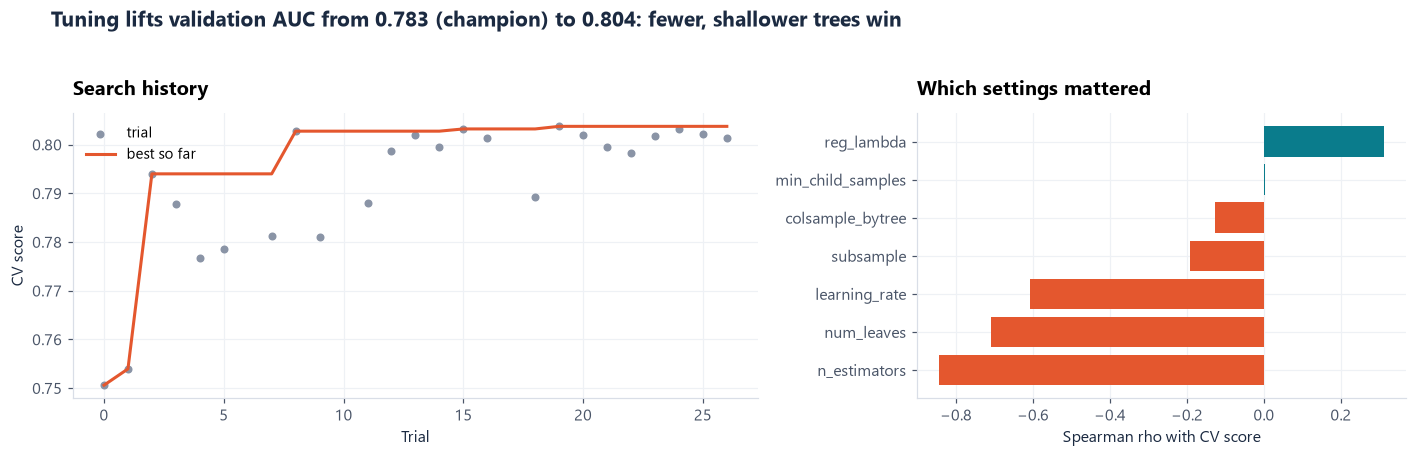

In [11]:
tune_idx = (np.arange(len(tr)), np.arange(len(tr), len(trva)))      # train on the Mar snapshot, score the Jun snapshot
t_tune = time.perf_counter()
best_params, study = select.tune_lgbm(trva[F.FEATS].reset_index(drop=True), trva["churn"].values, select.PredefinedSplits([tune_idx]),
                                      n_trials=30, timeout=240, seed=SEED)
print(f"Best validation AUC {study.best_value:.4f} after {len(study.trials)} trials ({time.perf_counter() - t_tune:.0f}s); params:",
      {k: (round(v, 4) if isinstance(v, float) else v) for k, v in best_params.items() if k not in ("verbose", "n_jobs", "random_state", "subsample_freq")})
fig = select.plot_optuna(study, f"Tuning lifts validation AUC from {auc_valid:.3f} (champion) to {study.best_value:.3f}: fewer, shallower trees win")
plt.show()

In [12]:
recency_only = make_pipeline(ColumnTransformer([("r", "passthrough", ["recency_days"])]), LogisticRegression())
CANDIDATES = {"Recency only": recency_only, "RFM rule": F.RFMRule(), f"Logistic (L2, C={BEST_C})": logistic(BEST_C),
              "Champion (production GBM)": HistGradientBoostingClassifier(**F.HGB_PARAMS), "Challenger (tuned LightGBM)": lgb.LGBMClassifier(**best_params)}
panel = pd.concat([S["cv"], tr, va])
n_cv, n_tr = len(S["cv"]), len(tr)
folds = select.PredefinedSplits([(np.arange(n_cv), np.arange(n_cv, n_cv + n_tr)),                      # Dec 2010 -> Mar 2011
                                 (np.arange(n_cv + n_tr), np.arange(n_cv + n_tr, len(panel)))])         # Dec + Mar -> Jun 2011
cvt = select.cv_compare(CANDIDATES, panel[F.FEATS].reset_index(drop=True), panel["churn"].values, folds)
cvt

,fit_seconds,roc_auc_mean,roc_auc_std,average_precision_mean,average_precision_std,brier_score_mean,brier_score_std
model,,,,,,,
Recency only,0.0300,0.7298,0.0160,0.7986,0.0174,0.2063,0.0084
RFM rule,0.0200,0.7796,0.0061,0.8221,0.0104,0.1797,0.0037
"Logistic (L2, C=0.01)",0.0300,0.7887,0.0096,0.8374,0.0150,0.1748,0.0046
Champion (production GBM),0.6300,0.7780,0.0133,0.8290,0.0106,0.1784,0.0061
Challenger (tuned LightGBM),0.1800,0.7916,0.0096,0.8394,0.0125,0.1725,0.0038


On the two out-of-time folds, the logistic (0.789) and the challenger (0.792) lead. The champion (0.778) is level with
the RFM rule (0.780), and recency alone trails (0.730). The challenger's second fold is optimistic, because it was tuned
on that fold. The decisive comparison is the untouched test snapshot below.

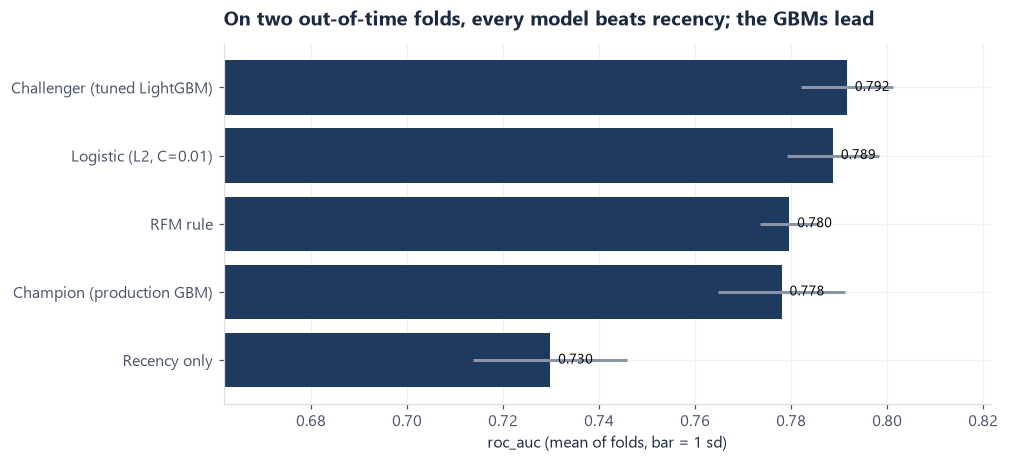

In [13]:
ax = select.plot_cv_compare(cvt, "roc_auc", title="On two out-of-time folds, every model beats recency; the GBMs lead")
plt.show()

**Would random cross-validation have told the same story?** Pool the training snapshots and cross-validate at random,
then by customer, and compare with the out-of-time estimates.

In [14]:
hgb = HistGradientBoostingClassifier(**F.HGB_PARAMS)
cv_random = cross_val_score(hgb, trva[F.FEATS], trva["churn"], cv=StratifiedKFold(5, shuffle=True, random_state=SEED), scoring="roc_auc").mean()
cv_group = cross_val_score(hgb, trva[F.FEATS], trva["churn"], cv=GroupKFold(5), groups=trva.index, scoring="roc_auc").mean()
honest = pd.Series({"Random 5-fold CV (pooled Mar + Jun)": cv_random, "Customer-grouped 5-fold CV": cv_group,
                    "Out of time: Mar -> Jun (validation)": auc_valid, "Out of time: Mar + Jun -> Sep (test)": mine["churn_auc_test"]}, name="AUC")
print(f"{len(set(tr.index) & set(va.index)):,} of {len(va):,} June customers also appear in the March snapshot")
honest.to_frame()

3,914 of 4,324 June customers also appear in the March snapshot


,AUC
Random 5-fold CV (pooled Mar + Jun),0.7933
Customer-grouped 5-fold CV,0.7877
Out of time: Mar -> Jun (validation),0.7830
Out of time: Mar + Jun -> Sep (test),0.7609


Random cross-validation says 0.793. The same model scores 0.761 on the next season, 3.2 points lower. Part of the gap is
customer overlap: 3,914 of the 4,324 June customers are also in the March snapshot, and grouping folds by customer
lowers the estimate to 0.788. The rest is time: a model judged on a later season does worse than one judged on a shuffled
mix of the seasons it trained on. Only out-of-time numbers are quoted in this repo.

## 5. The untouched test snapshot: champion vs challenger

Every candidate is refit on Mar + Jun 2011 (as the ETL does) and scored once on 1 Sep 2011.

In [15]:
preds = {}
fitted = {}
for name, m in CANDIDATES.items():
    fitted[name] = m.fit(trva[F.FEATS], trva["churn"])
    preds[name] = fitted[name].predict_proba(te[F.FEATS])[:, 1]
assert abs(roc_auc_score(y_te, preds["Champion (production GBM)"]) - pub["churn_auc_test"]) <= 0.005
mt = evaluate.metrics_table(y_te, preds, n_boot=500, seed=SEED)
mt

,AUC,AUC 95% CI,PR AUC,PR AUC 95% CI,KS,Brier,Log loss
model,,,,,,,
Recency only,0.7080,0.692 - 0.724,0.6794,0.661 - 0.699,0.3426,0.2399,0.6975
RFM rule,0.7581,0.744 - 0.772,0.7102,0.694 - 0.726,0.4056,0.2165,0.6285
"Logistic (L2, C=0.01)",0.7701,0.756 - 0.784,0.7425,0.724 - 0.759,0.4090,0.2107,0.6124
Champion (production GBM),0.7609,0.747 - 0.775,0.7203,0.704 - 0.739,0.4116,0.2153,0.6292
Challenger (tuned LightGBM),0.7729,0.759 - 0.786,0.7442,0.727 - 0.761,0.4200,0.2101,0.6093


In [16]:
CH, CL = "Champion (production GBM)", "Challenger (tuned LightGBM)"
LOGIT = [k for k in preds if k.startswith("Logistic")][0]
tests = pd.DataFrame({f"{a} vs {b}": evaluate.paired_auc_test(y_te, preds[a], preds[b], n=1000, seed=SEED)
                      for a, b in ((CL, CH), (LOGIT, CH), (CL, LOGIT), (CH, "RFM rule"), (CH, "Recency only"))}).T
tests

,delta_auc,ci_low,ci_high,p_value_one_sided
Challenger (tuned LightGBM) vs Champion (production GBM),0.0120,0.0074,0.0171,0.0000
"Logistic (L2, C=0.01) vs Champion (production GBM)",0.0093,0.0024,0.0163,0.0020
"Challenger (tuned LightGBM) vs Logistic (L2, C=0.01)",0.0028,-0.0012,0.0066,0.0970
Champion (production GBM) vs RFM rule,0.0028,-0.0056,0.0108,0.2630
Champion (production GBM) vs Recency only,0.0528,0.0410,0.0636,0.0000


**Decision.**

* **The production champion is the weakest learned model on the test snapshot.** The tuned LightGBM beats it by +0.012
  AUC (CI +0.007 to +0.017) and the regularised logistic by +0.009 (CI +0.002 to +0.016). The champion is not
  distinguishable from the RFM table (+0.003, CI -0.006 to +0.011), although it still beats recency alone by +0.053.
* **Why: over-fitting.** The champion grows 300 trees with 15 leaves and 40 rows per leaf on 8,584 rows; sklearn's
  automatic early stopping only switches on above 10,000 rows, so nothing stops it. Optuna's best
  model uses 200 trees, 9 leaves, 110 rows per leaf and half the learning rate. In the search history, every
  capacity setting (trees, leaves, learning rate) correlates negatively with validation AUC.
* **Recommendation: promote the regularised logistic model.** It matches the tuned LightGBM within noise (+0.003, CI
  -0.001 to +0.007, p = 0.10), it can be explained coefficient by coefficient, and it is cheap to monitor and retrain.
  The same ranking appeared on the two out-of-time CV folds, so this is not a one-snapshot accident.
* **The published numbers do not change.** The Power BI report keeps quoting the production model (0.7609). The switch
  is a champion/challenger finding for the next release: shadow-score one quarter, check calibration and segment AUC,
  then switch. The rest of this notebook uses the production champion, so every number ties back to the report;
  section 10 shows what the swap is worth in money.

## 6. Calibration: the seasonal shift

AUC only measures ranking. The retention budget in section 10 multiplies probabilities by customer value, so the
probabilities themselves must be right. Training snapshots churn at 63%; the test snapshot at 50%.

In [17]:
print(f"Test snapshot: mean predicted churn {p_champ.mean():.3f} vs observed {y_te.mean():.3f}")
# fix 1: isotonic regression fitted on the June validation snapshot (scores from the March-only model)
iso = IsotonicRegression(out_of_bounds="clip").fit(champ_mar.predict_proba(va[F.FEATS])[:, 1], va["churn"])
p_iso = iso.predict(p_champ)
# fix 2: shift the intercept to an autumn base rate known on 1 Sep 2011:
#        latest matured rate (Jun 2011 snapshot) x last year's seasonal ratio (Sep 2010 / Jun 2010 snapshots)
ly = {d: F.snapshot(lines, d, orders)["churn"].mean() for d in ("2010-06-01", "2010-09-01")}
target_rate = va["churn"].mean() * ly["2010-09-01"] / ly["2010-06-01"]
p_cal = F.shift_to_rate(p_champ, target_rate)
print(f"Seasonal estimate known on the scoring date: {va['churn'].mean():.3f} x ({ly['2010-09-01']:.3f} / {ly['2010-06-01']:.3f}) = {target_rate:.3f}")
cal = pd.DataFrame({name: {"mean_predicted": p.mean(), "observed": y_te.mean(), "calibration_ratio": p.mean() / y_te.mean(),
                           "brier": brier_score_loss(y_te, p), "log_loss": log_loss(y_te, np.clip(p, 1e-6, 1 - 1e-6)), "auc": roc_auc_score(y_te, p)}
                    for name, p in {"Raw champion": p_champ, "Isotonic (fitted on Jun 2011)": p_iso, "Seasonal intercept shift": p_cal}.items()}).T
cal

Test snapshot: mean predicted churn 0.641 vs observed 0.505


Seasonal estimate known on the scoring date: 0.634 x (0.417 / 0.503) = 0.525


,mean_predicted,observed,calibration_ratio,brier,log_loss,auc
Raw champion,0.6406,0.5046,1.2694,0.2153,0.6292,0.7609
Isotonic (fitted on Jun 2011),0.6270,0.5046,1.2425,0.2112,0.6200,0.7602
Seasonal intercept shift,0.5251,0.5046,1.0406,0.1966,0.5754,0.7609


The raw champion over-predicts by 13.6 points (calibration ratio 1.27). Isotonic regression fitted on the June snapshot
barely moves it (1.24): June churns at 63%, like the training data, so it carries no information about autumn. The
seasonal intercept shift uses three numbers known on 1 Sep 2011 (the Jun 2011 rate, and last year's Sep/Jun ratio). It
estimates 52.5% against an actual 50.5% and cuts the Brier score from 0.215 to 0.197 and log loss from 0.629 to 0.575.
The AUC is unchanged by construction. From here on, probabilities are the shifted ones.

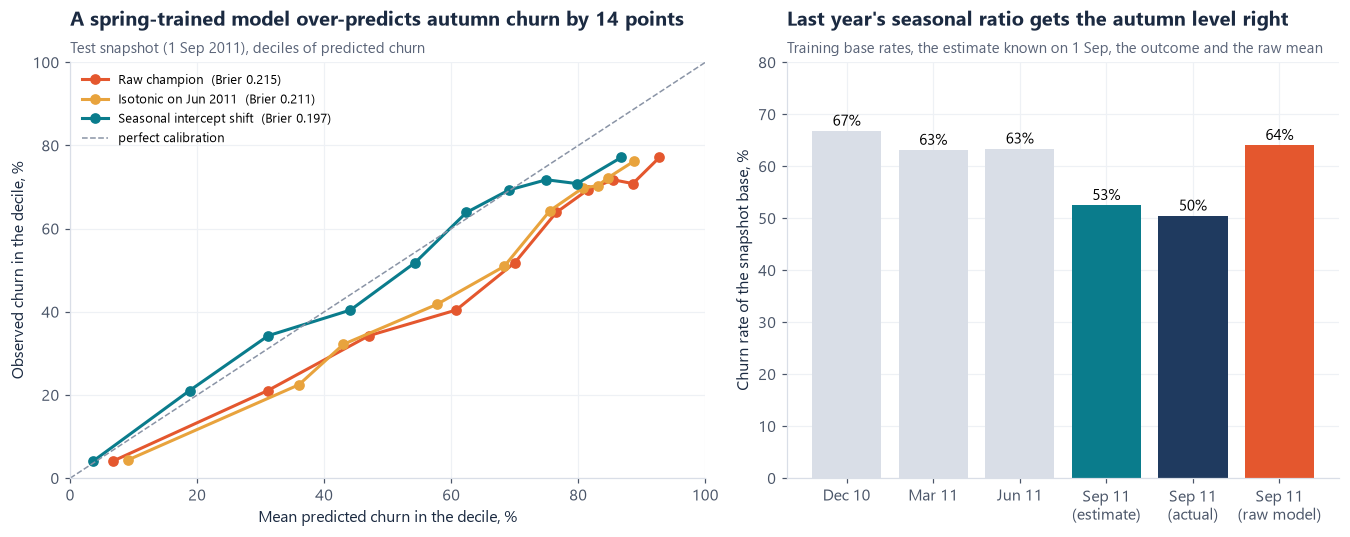

In [18]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [1.15, 1]})
for (name, p), c in zip({"Raw champion": p_champ, "Isotonic on Jun 2011": p_iso, "Seasonal intercept shift": p_cal}.items(),
                        (PALETTE["coral"], PALETTE["amber"], PALETTE["teal"])):
    ct = evaluate.calibration_table(y_te, p, 10)
    a1.plot(ct["predicted"] * 100, ct["observed"] * 100, marker="o", color=c, label=f"{name}  (Brier {brier_score_loss(y_te, p):.3f})")
a1.plot([0, 100], [0, 100], ls="--", color=PALETTE["grey"], lw=1, label="perfect calibration")
a1.set(xlabel="Mean predicted churn in the decile, %", ylabel="Observed churn in the decile, %", xlim=(0, 100), ylim=(0, 100))
a1.legend(loc="upper left", fontsize=8.5)
headline(a1, f"A spring-trained model over-predicts autumn churn by {(p_champ.mean() - y_te.mean()) * 100:.0f} points",
         "Test snapshot (1 Sep 2011), deciles of predicted churn")
ratio = np.r_[S["cv"]["churn"].mean(), tr["churn"].mean(), va["churn"].mean()]
lab = ["Dec 10", "Mar 11", "Jun 11"]
a2.bar(lab, ratio * 100, color=PALETTE["light"])
a2.bar(["Sep 11\n(estimate)"], [target_rate * 100], color=PALETTE["teal"])
a2.bar(["Sep 11\n(actual)"], [y_te.mean() * 100], color=PALETTE["navy"])
a2.bar(["Sep 11\n(raw model)"], [p_champ.mean() * 100], color=PALETTE["coral"])
for i, v in enumerate(list(ratio * 100) + [target_rate * 100, y_te.mean() * 100, p_champ.mean() * 100]):
    a2.text(i, v + 1, f"{v:.0f}%", ha="center", fontsize=9.5)
a2.set_ylabel("Churn rate of the snapshot base, %"); a2.set_ylim(0, 80)
headline(a2, "Last year's seasonal ratio gets the autumn level right", "Training base rates, the estimate known on 1 Sep, the outcome and the raw mean")
fig.tight_layout()
savefig(fig, "02-calibration", FIG); plt.show()

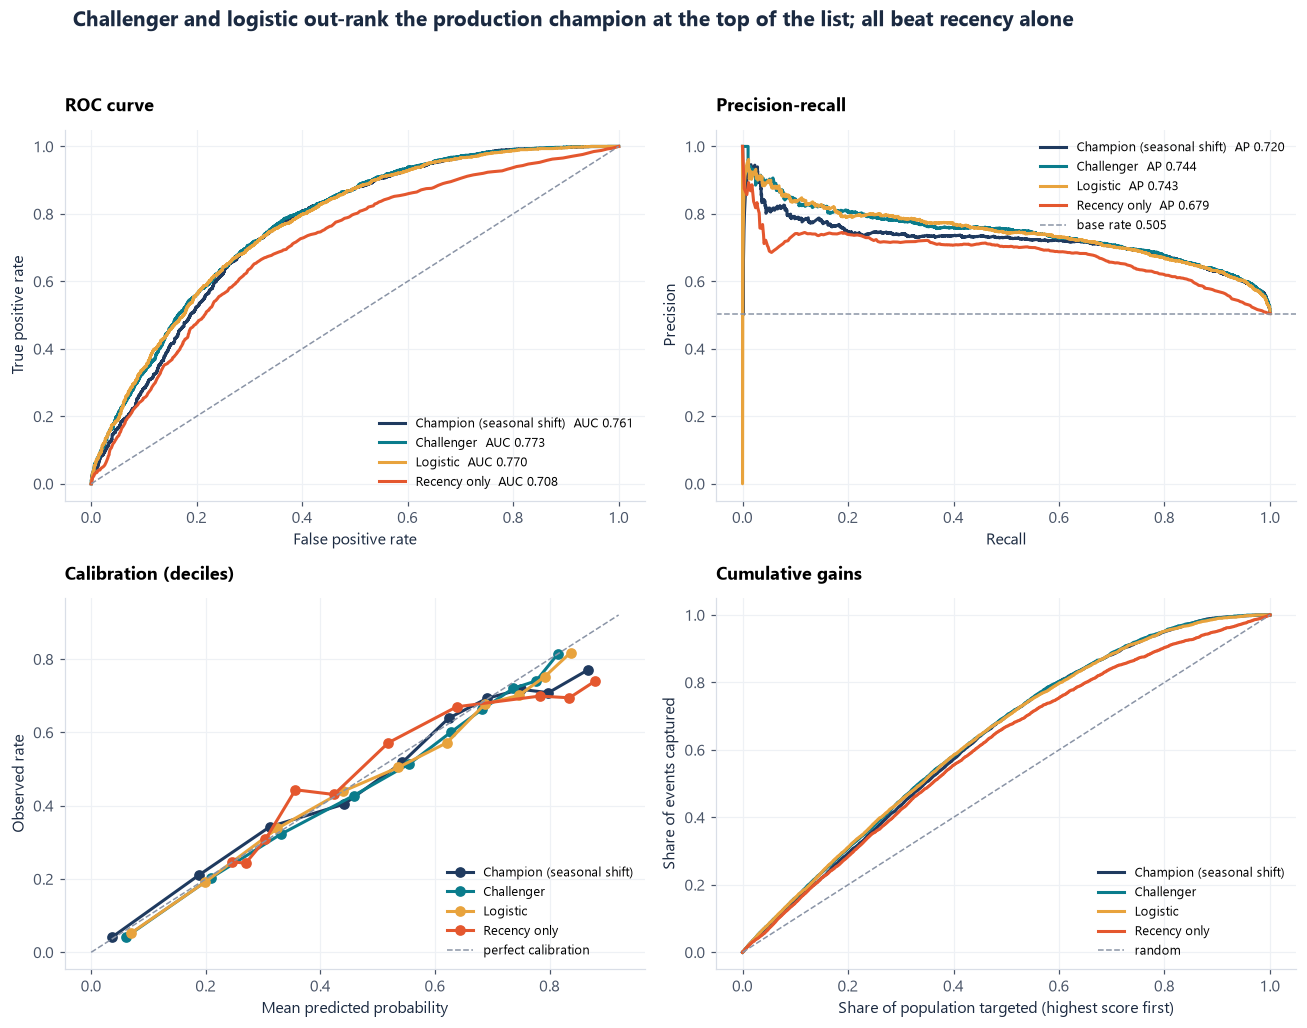

In [19]:
fig = evaluate.plot_binary_panel(y_te, {"Champion (seasonal shift)": p_cal, "Challenger": F.shift_to_rate(preds[CL], target_rate),
                                        "Logistic": F.shift_to_rate(preds[LOGIT], target_rate), "Recency only": F.shift_to_rate(preds["Recency only"], target_rate)},
                                 suptitle="Challenger and logistic out-rank the production champion at the top of the list; all beat recency alone")
plt.show()

## 7. Ranking value and segment robustness

In [20]:
value = te["spend_365"].clip(lower=0).values
gt = evaluate.gains_table(y_te, p_cal, value=value)
gt

,rows,events,mean_score,value,rate,lift,cum_capture,cum_value_capture
decile,,,,,,,,
1,433,334,0.8678,"181,105.3600",0.7714,1.5286,0.1531,0.0231
2,432,306,0.7979,"175,164.4300",0.7083,1.4037,0.2933,0.0454
3,432,310,0.7497,"225,781.9100",0.7176,1.4220,0.4354,0.0741
4,433,300,0.6907,"233,359.6100",0.6928,1.3730,0.5729,0.1038
5,432,276,0.6239,"338,215.7400",0.6389,1.2661,0.6994,0.1469
6,432,224,0.5432,"343,535.6900",0.5185,1.0275,0.8020,0.1906
7,433,175,0.4411,"426,894.7300",0.4042,0.8009,0.8822,0.2450
8,432,148,0.3119,"679,399.5400",0.3426,0.6789,0.9500,0.3315
9,432,91,0.1881,"1,043,806.9300",0.2106,0.4174,0.9918,0.4644


The ranking concentrates churners as the report says: 77% churn in the top decile (lift 1.53) and 43.5% of all churners in
the top 30%. The value column shows the catch. The riskiest 30% hold only 7.4% of 12-month spend, while the safest decile
alone holds 54%. The customers most likely to leave are mostly one-order, low-spend customers, which matters in
section 10.

In [21]:
seg = F.segments(te).assign(churn=y_te, p=p_cal)
seg_tables = {s: evaluate.segment_performance(seg, s, "churn", "p", min_n=100) for s in ("market", "value_tier", "tenure_band")}
for s, t in seg_tables.items():
    t["auc_ci"] = [f"{lo:.3f} - {hi:.3f}" for lo, hi in
                   (evaluate.bootstrap_ci(seg.loc[seg[s] == lvl, "churn"], seg.loc[seg[s] == lvl, "p"], n=300)[1:] for lvl in t.index)]
segperf = pd.concat(seg_tables, names=["segment", "level"])
segperf

rows  base_rate  mean_pred  calibration_ratio    auc         auc_ci
segment     level                                                                              
market      Outside UK       387     0.4755     0.4711             0.9908 0.7789  0.735 - 0.824
            UK              3937     0.5075     0.5304             1.0451 0.7589  0.740 - 0.774
value_tier  Bottom 50%      2162     0.6901     0.6942             1.0059 0.6074  0.582 - 0.635
            Middle 30%      1297     0.4279     0.4731             1.1057 0.6628  0.634 - 0.689
            Top 20%          865     0.1561     0.1803             1.1555 0.7821  0.741 - 0.824
tenure_band 6-12 months     1239     0.6215     0.6559             1.0554 0.7183  0.692 - 0.749
            Over 12 months  2399     0.4352     0.4536             1.0424 0.7617  0.742 - 0.780
            Under 6 months   686     0.5364     0.5386             1.0041 0.7326  0.693 - 0.767

Inside a value tier, ranking is harder (AUC 0.61-0.78) because the tier itself carries much of the signal. It is weakest in
the bottom half by value, where most customers have a single order and little history to separate them. Calibration holds
within 0.99-1.16 in every segment; the largest gap is a slight over-prediction for the top 20% by value (18% predicted vs
16% observed). Customers outside the UK are ranked as well as UK customers (0.78 vs 0.76).

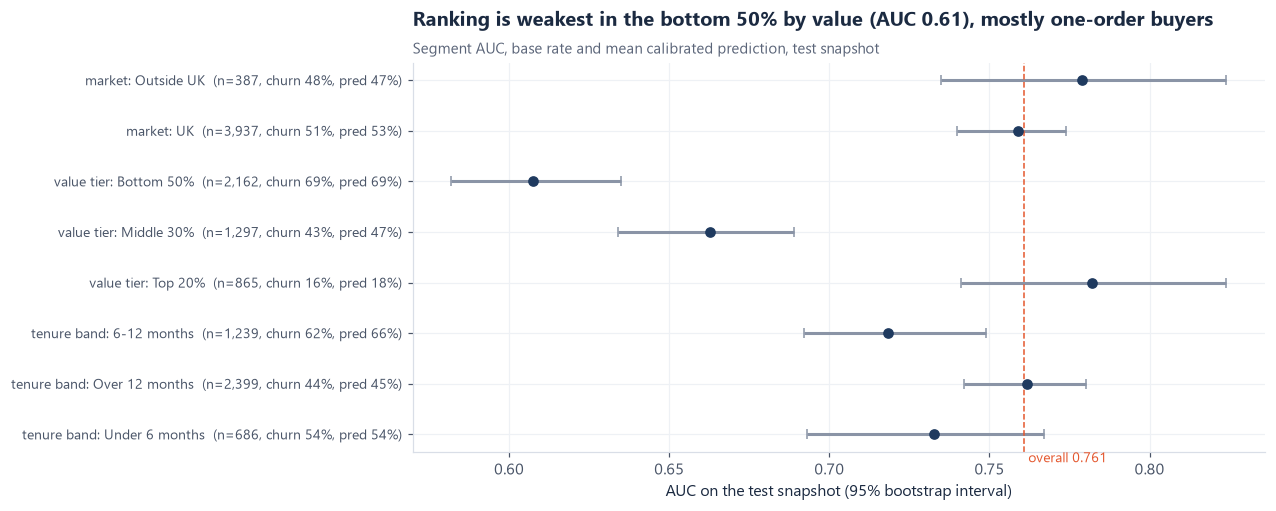

In [22]:
fig, ax = plt.subplots(figsize=(10, 4.6))
sp = segperf.reset_index()
yy = np.arange(len(sp))
lo = sp["auc_ci"].str.split(" - ").str[0].astype(float); hi = sp["auc_ci"].str.split(" - ").str[1].astype(float)
ax.errorbar(sp["auc"], yy, xerr=[sp["auc"] - lo, hi - sp["auc"]], fmt="o", color=PALETTE["navy"], ecolor=PALETTE["grey"], capsize=3)
ax.axvline(mine["churn_auc_test"], color=PALETTE["coral"], ls="--", lw=1)
ax.text(mine["churn_auc_test"], len(sp) - 0.45, f" overall {mine['churn_auc_test']:.3f}", color=PALETTE["coral"], fontsize=9)
ax.set_yticks(yy, [f"{a}: {b}  (n={n:,}, churn {r:.0%}, pred {q:.0%})" for a, b, n, r, q in
                   zip(sp["segment"].str.replace("_", " "), sp["level"], sp["rows"], sp["base_rate"], sp["mean_pred"])], fontsize=9)
ax.invert_yaxis(); ax.set_xlabel("AUC on the test snapshot (95% bootstrap interval)")
worst = segperf["auc"].idxmin()
headline(ax, f"Ranking is weakest in the {worst[1].lower()} by value (AUC {segperf['auc'].min():.2f}), mostly one-order buyers",
         "Segment AUC, base rate and mean calibrated prediction, test snapshot")
plt.show()

## 8. What drives the score

SHAP values on a 3,000-customer sample of the test snapshot (log-odds scale), cross-checked against permutation
importance (drop in test AUC when a feature is shuffled).

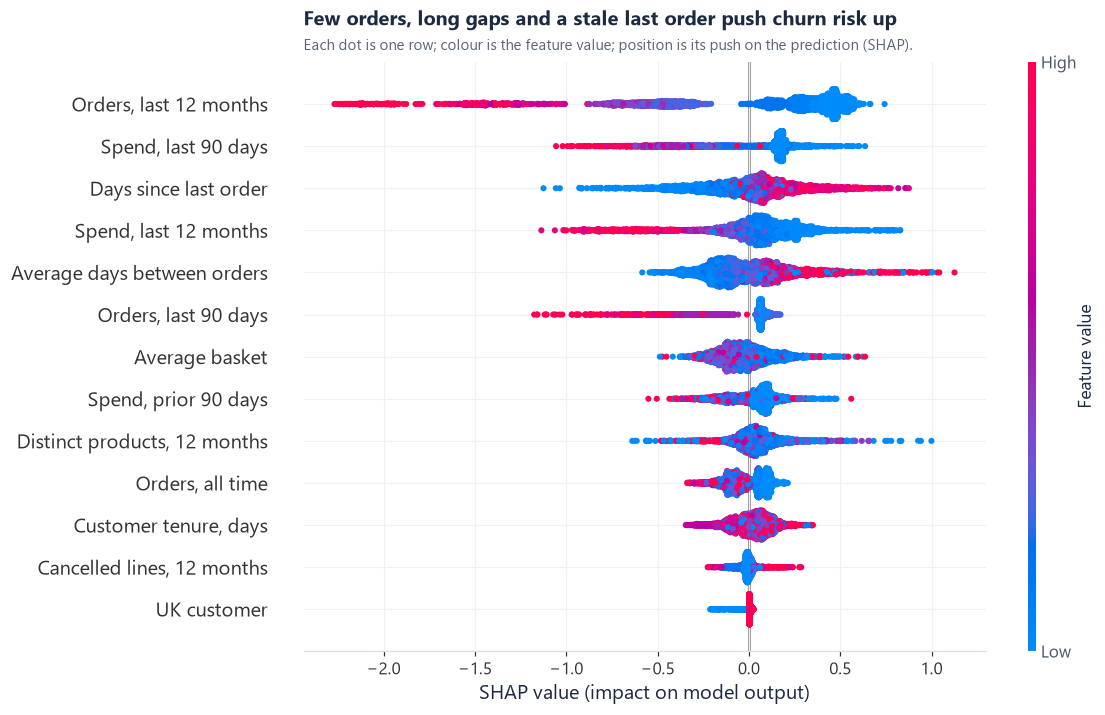

In [23]:
import copy
e = explain.shap_explanation(champion, te[F.FEATS], sample=3000, seed=SEED)
e_lab = copy.copy(e)                                       # same values, readable names for the charts
e_lab.feature_names = [F.FEAT_LABEL[f] for f in e.feature_names]
fig = explain.plot_shap_beeswarm(e_lab, max_display=13, title="Few orders, long gaps and a stale last order push churn risk up")
savefig(fig, "02-shap", FIG); plt.show()

In [24]:
shap_imp = explain.shap_importance(e)
perm = explain.permutation_table(champion, te[F.FEATS], y_te, n_repeats=5, seed=SEED, labels=F.FEAT_LABEL)
imp = shap_imp.join(perm[["drop_mean", "drop_std"]])
imp["shap_rank"], imp["perm_rank"] = imp["mean_abs_shap"].rank(ascending=False).astype(int), imp["drop_mean"].rank(ascending=False).astype(int)
FAMILY = {"recency_days": "Recency", "avg_gap_days": "Recency", "orders_365": "Frequency", "orders_90": "Frequency", "orders_all": "Frequency",
          "spend_365": "Spend", "spend_90": "Spend", "spend_prev_90": "Spend", "avg_basket": "Spend", "products_365": "Breadth",
          "cancel_lines_365": "Breadth", "tenure_days": "Tenure", "is_uk": "Market"}
fam = imp.groupby(imp.index.map(FAMILY))[["share"]].sum().sort_values("share", ascending=False).rename(columns={"share": "share_of_mean_abs_shap"})
print("Spearman rank correlation, SHAP vs permutation:", round(imp["mean_abs_shap"].corr(imp["drop_mean"], method="spearman"), 3))
display(imp.round(4)); fam

Spearman rank correlation, SHAP vs permutation: 0.758


,mean_abs_shap,share,drop_mean,drop_std,shap_rank,perm_rank
feature,,,,,,
orders_365,0.5225,0.2624,0.0238,0.0025,1,1
spend_90,0.2406,0.1208,0.0070,0.0019,2,5
recency_days,0.1950,0.0979,0.0096,0.0025,3,4
spend_365,0.1947,0.0978,0.0120,0.0017,4,3
avg_gap_days,0.1783,0.0896,0.0167,0.0005,5,2
orders_90,0.1352,0.0679,-0.0001,0.0004,6,11
avg_basket,0.1112,0.0558,0.0033,0.0012,7,8
spend_prev_90,0.1033,0.0519,0.0047,0.0013,8,7
products_365,0.0983,0.0494,-0.0013,0.0015,9,13


,share_of_mean_abs_shap
feature,
Frequency,0.3741
Spend,0.3263
Recency,0.1875
Breadth,0.0648
Tenure,0.0416
Market,0.0058


SHAP and permutation importance agree at the top: 12-month orders come first in both, and the rank correlation is 0.76.
They disagree on 90-day orders and distinct products. The model uses those features (SHAP), but shuffling them costs no
AUC, because correlated features carry the same information. By family, frequency (37% of mean |SHAP|) and spend (33%)
dominate and recency adds 19%. Country contributes almost nothing (0.6%).

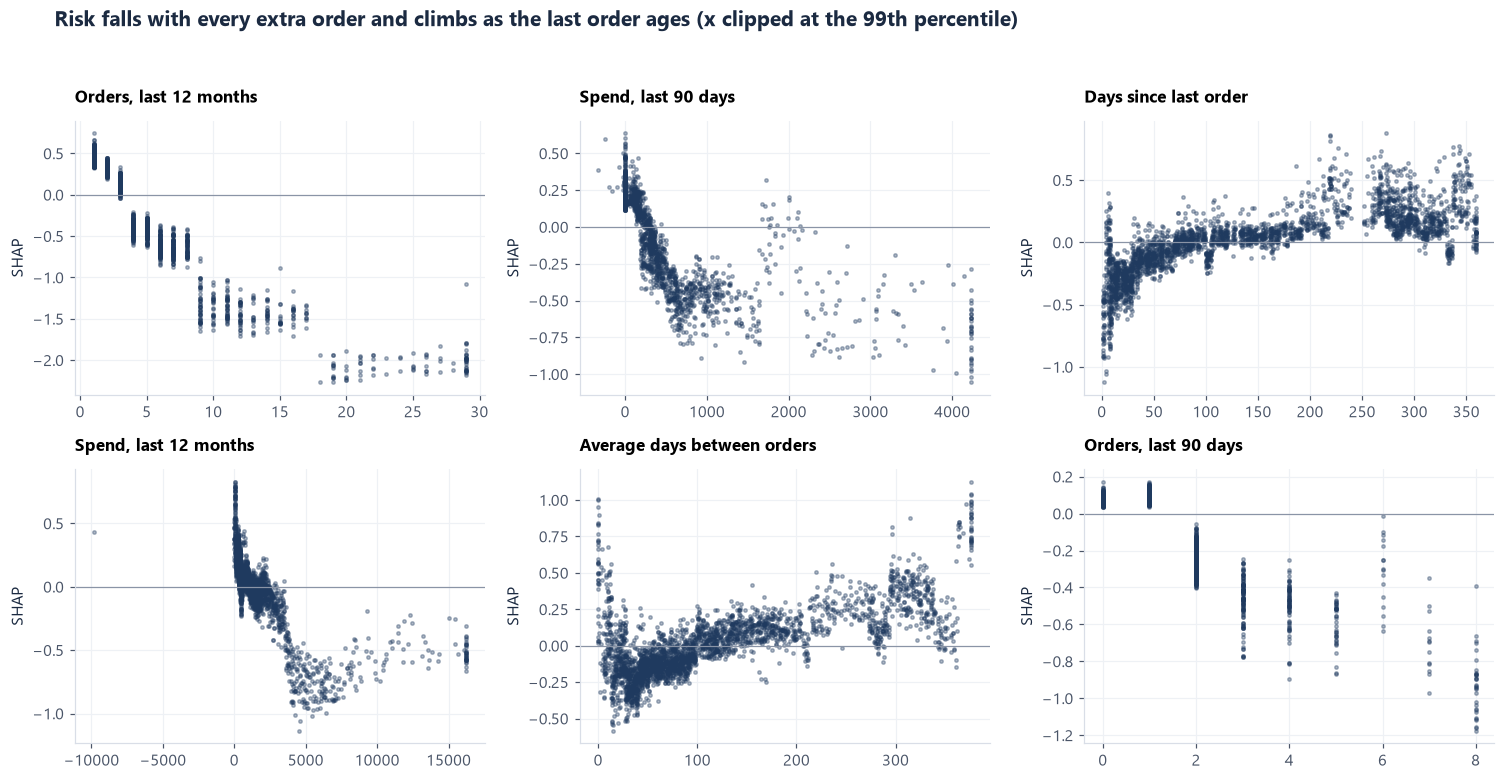

In [25]:
top = list(shap_imp.index[:6])
e_clip = copy.copy(e_lab)                                  # display only: clip x at the 99th percentile so heavy tails don't flatten the view
e_clip.data = np.column_stack([np.clip(e.data[:, j], None, np.nanpercentile(e.data[:, j], 99)) for j in range(e.data.shape[1])])
fig = explain.plot_shap_dependence(e_clip, [F.FEAT_LABEL[f] for f in top], ncols=3,
                                   title="Risk falls with every extra order and climbs as the last order ages (x clipped at the 99th percentile)")
plt.show()

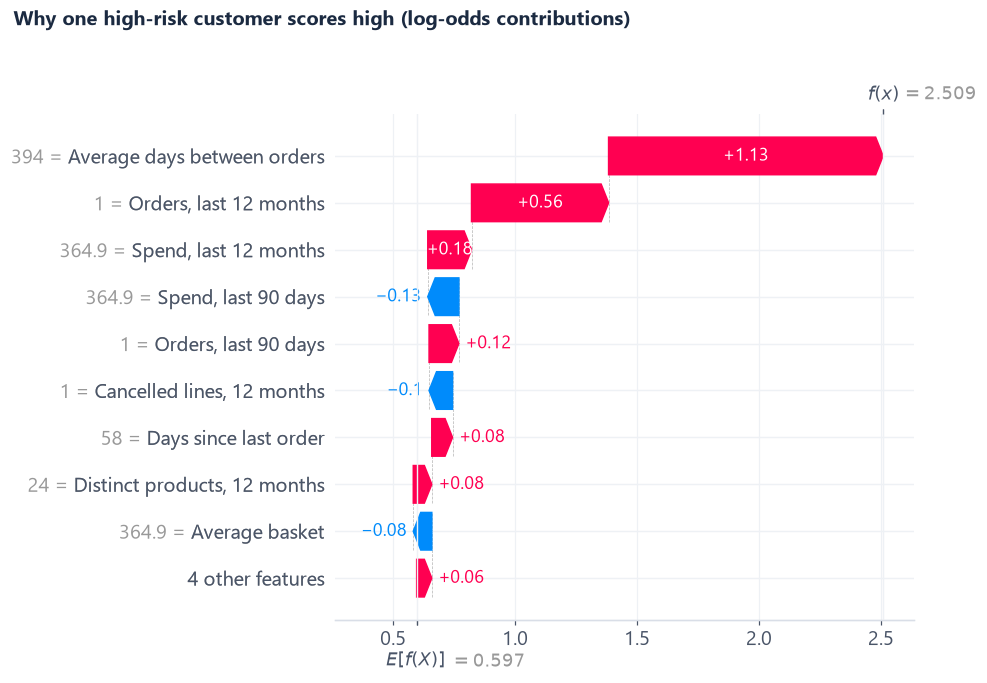

In [26]:
pe = e.values.sum(1) + e.base_values
i_high = int(np.argsort(pe)[-int(0.05 * len(pe))])          # a customer at the 95th percentile of risk in the sample
fig = explain.plot_shap_waterfall(e_lab, i_high, title="Why one high-risk customer scores high (log-odds contributions)")
plt.show()

This customer ordered once in the last year, 58 days before the snapshot, and has averaged 394 days between orders. The
long gap alone adds 1.13 to the log-odds of churn. The model reads them as an occasional buyer, not a lapsing regular.

## 9. Error analysis: who is mis-ranked?

Two errors cost money. **False alarms**: customers in the riskiest 30% who bought anyway (a contact wasted, maybe a
discount given away). **Missed churners**: customers in the safest half who left (no chance to save them).

In [27]:
rk = pd.Series(p_cal, index=te.index).rank(pct=True, ascending=False)
grp = np.select([(rk <= 0.3) & (y_te == 1), (rk <= 0.3) & (y_te == 0), (rk > 0.5) & (y_te == 1), (rk > 0.5) & (y_te == 0)],
                ["Flagged, churned", "False alarm (flagged, bought)", "Missed churner (safe half, churned)", "Safe half, bought"], "Middle 20%")
prof = te.assign(group=grp, same_season_ly=F.same_season_orders(orders, te.index, F.SNAPSHOTS["test"]) > 0, value=value)
errors = prof.groupby("group").agg(customers=("churn", "size"), recency_days=("recency_days", "median"), orders_365=("orders_365", "median"),
                                   avg_gap_days=("avg_gap_days", "median"), spend_365=("spend_365", "median"), tenure_days=("tenure_days", "median"),
                                   bought_same_season_last_year=("same_season_ly", "mean"), uk=("is_uk", "mean"))
errors.loc[["Flagged, churned", "False alarm (flagged, bought)", "Missed churner (safe half, churned)", "Safe half, bought"]]

,customers,recency_days,orders_365,avg_gap_days,spend_365,tenure_days,bought_same_season_last_year,uk
group,,,,,,,,
"Flagged, churned",950,274.0000,1.0000,213.5000,229.3650,315.0000,0.5779,0.9263
"False alarm (flagged, bought)",347,276.0000,1.0000,175.0000,282.3700,332.0000,0.6542,0.9395
"Missed churner (safe half, churned)",656,64.0000,3.0000,71.7083,833.2800,462.5000,0.6021,0.8872
"Safe half, bought",1506,38.0000,5.0000,49.6111,"1,744.4100",524.5000,0.7457,0.8944


**False alarms look exactly like the churners they sit next to.** Median recency is 276 vs 274 days, both groups have one
order in the last year, and spend is similar (£282 vs £229). Nothing in these 13 purchase-history features separates them,
so this is the error floor at this data granularity. One hint: 65% of false alarms bought in the same season last year,
vs 58% of correctly flagged churners. Some "dormant" customers are seasonal buyers who come back for Christmas.

**Missed churners are a different group.** They are regular customers (median 3 orders, last order 64 days ago, £833
spend) who stop without warning. They are worth more than the average flagged customer, and their purchase history gives
no signal. Service data (complaints, late deliveries, price changes) is where to look.

The obvious fix for the first group is a same-season feature (orders in the label window one year earlier). It is
tested below, on validation first.

In [28]:
def add_season(f, t):
    return f.assign(same_season_ly=F.same_season_orders(orders, f.index, t))


FEATS_S = F.FEATS + ["same_season_ly"]
tr_s, va_s, te_s = add_season(tr, F.SNAPSHOTS["train"]), add_season(va, F.SNAPSHOTS["valid"]), add_season(te, F.SNAPSHOTS["test"])
v_base = auc_valid
v_seas = roc_auc_score(va_s["churn"], HistGradientBoostingClassifier(**F.HGB_PARAMS).fit(tr_s[FEATS_S], tr_s["churn"]).predict_proba(va_s[FEATS_S])[:, 1])
m_seas = HistGradientBoostingClassifier(**F.HGB_PARAMS).fit(pd.concat([tr_s, va_s])[FEATS_S], pd.concat([tr_s, va_s])["churn"])
p_seas = m_seas.predict_proba(te_s[FEATS_S])[:, 1]
season_test = evaluate.paired_auc_test(y_te, p_seas, p_champ, n=1000, seed=SEED)
print(f"Validation (Mar -> Jun) AUC: {v_base:.4f} -> {v_seas:.4f} with the same-season feature")
print(f"Test AUC: {mine['churn_auc_test']:.4f} -> {roc_auc_score(y_te, p_seas):.4f}; paired delta {season_test['delta_auc']:+.4f} "
      f"(95% CI {season_test['ci_low']:+.4f} to {season_test['ci_high']:+.4f})")

Validation (Mar -> Jun) AUC: 0.7830 -> 0.7821 with the same-season feature
Test AUC: 0.7609 -> 0.7628; paired delta +0.0019 (95% CI -0.0005 to +0.0044)


Not adopted. Validation AUC does not improve (0.7830 to 0.7821), and the test gain (+0.002, CI -0.001 to +0.004) is
within noise. In this data, seasonality changes *how many* customers churn, which calibration handles, more than *which*
customers churn.

## 10. Decision: how much retention budget, for whom?

A score becomes money only through an action. Assumptions (none are in the data, so each is varied below):

| Assumption | Value | Why |
|---|---|---|
| Value of keeping a customer | 30% gross margin x their last-12-month spend | One more year at the current rate; typical gift-wholesale margin 25-40% |
| Save rate | 10% of contacted would-be churners are retained | A typical retention-offer effect; **the number the A/B test must measure** |
| Cost per contact | £10 | Voucher cost (also paid by customers who would have bought anyway) plus handling |

Net value of contacting the top *k* = save rate x margin value of the churners reached - cost x *k*, backtested on the
test snapshot. Two orderings: by churn probability, and by **expected margin at risk** = P(churn) x margin value.

In [29]:
MARGIN, SAVE, COST = 0.30, 0.10, 10.0
mval = MARGIN * value


def net_curve(order, y, v, save=SAVE, cost=COST):
    """Net value of contacting the first k customers in `order`, for every k (index 0 = nobody)."""
    return np.r_[0, np.cumsum(save * v[order] * y[order] - cost)]


ev = p_cal * mval
orders_by = {"Rank by churn probability": np.argsort(-p_cal, kind="stable"), "Rank by expected margin at risk": np.argsort(-ev, kind="stable")}
curves = {k: net_curve(o, y_te, mval) for k, o in orders_by.items()}
share = np.arange(len(y_te) + 1) / len(y_te)
rng = np.random.default_rng(SEED)
boot = []
for _ in range(300):
    ix = rng.integers(0, len(y_te), len(y_te))
    o = np.argsort(-ev[ix], kind="stable")
    boot.append(net_curve(o, y_te[ix], mval[ix]))
boot = np.array(boot)
band = np.percentile(boot, [5, 95], axis=0)
best = {k: (int(np.argmax(c)), float(c.max())) for k, c in curves.items()}
for k, (kk, v) in best.items():
    print(f"{k}: best at top {kk / len(y_te):.0%} ({kk:,} customers), net £{v:,.0f} per quarter-cohort")
k_ev = best["Rank by expected margin at risk"][0]
print(f"90% bootstrap band for the value-ranked net at its optimum: £{band[0][k_ev]:,.0f} to £{band[1][k_ev]:,.0f}")

Rank by churn probability: best at top 89% (3,828 customers), net £5,844 per quarter-cohort
Rank by expected margin at risk: best at top 42% (1,801 customers), net £15,163 per quarter-cohort
90% bootstrap band for the value-ranked net at its optimum: £11,565 to £18,521


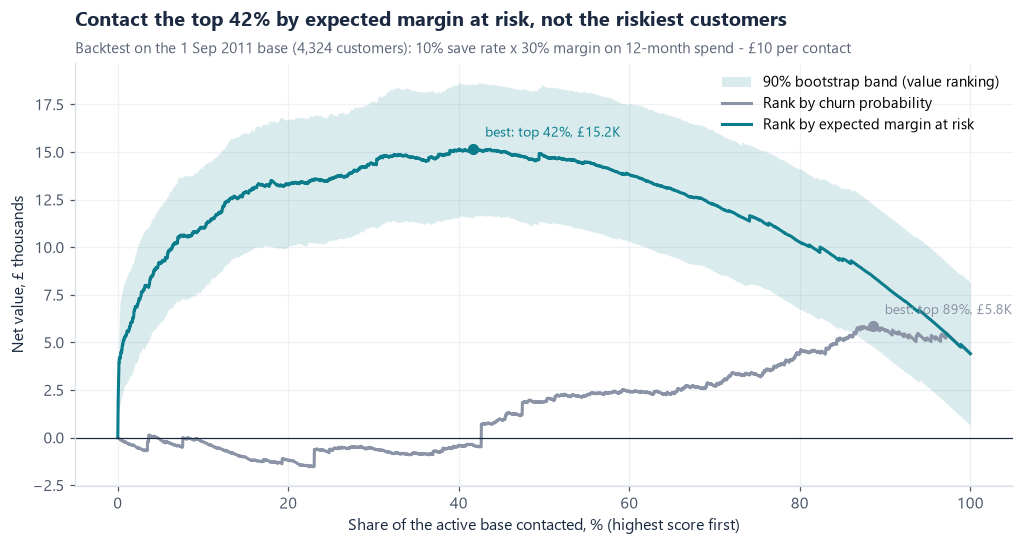

,test_auc,best_share,net_value_gbp
Champion (production GBM),0.7609,0.4165,"15,162.7715"
"Logistic (L2, C=0.01)",0.7701,0.3349,"15,394.7230"
Challenger (tuned LightGBM),0.7729,0.4121,"15,601.8306"
RFM rule,0.7581,0.4147,"13,932.6466"


In [30]:
fig, ax = plt.subplots(figsize=(11, 5))
ax.fill_between(share * 100, band[0] / 1e3, band[1] / 1e3, color=PALETTE["teal"], alpha=0.15, lw=0, label="90% bootstrap band (value ranking)")
for (k, c), col in zip(curves.items(), (PALETTE["grey"], PALETTE["teal"])):
    ax.plot(share * 100, c / 1e3, color=col, label=k)
    kk, v = best[k]
    ax.scatter([kk / len(y_te) * 100], [v / 1e3], color=col, zorder=4, s=40)
    ax.annotate(f"best: top {kk / len(y_te):.0%}, £{v / 1e3:,.1f}K", (kk / len(y_te) * 100, v / 1e3), textcoords="offset points", xytext=(8, 8), fontsize=9, color=col)
ax.axhline(0, color=PALETTE["ink"], lw=0.8)
ax.set_xlabel("Share of the active base contacted, % (highest score first)"); ax.set_ylabel("Net value, £ thousands")
ax.legend(loc="upper right")
headline(ax, f"Contact the top {k_ev / len(y_te):.0%} by expected margin at risk, not the riskiest customers",
         f"Backtest on the 1 Sep 2011 base ({len(y_te):,} customers): {SAVE:.0%} save rate x {MARGIN:.0%} margin on 12-month spend - £{COST:.0f} per contact")
savefig(fig, "02-retention-budget", FIG); plt.show()

swap = {}
for name in (CH, LOGIT, CL, "RFM rule"):
    q = F.shift_to_rate(preds[name], target_rate)
    c = net_curve(np.argsort(-(q * mval), kind="stable"), y_te, mval)
    swap[name] = {"test_auc": roc_auc_score(y_te, preds[name]), "best_share": np.argmax(c) / len(y_te), "net_value_gbp": c.max()}
swap = pd.DataFrame(swap).T
swap

Ranking by expected margin at risk earns £15.2K at its optimum (top 42%, 1,801 customers). The best list ranked by churn
probability earns £5.8K and needs 89% of the base. The riskiest customers are worth little, and contacting them mostly
spends £10 on someone with £50-£100 of margin at stake. The better models add £0.2K-£0.4K a quarter over the
champion: worth having, but an order of magnitude smaller than the choice of ranking.

How sensitive is the recommendation to the two assumptions nobody knows yet?

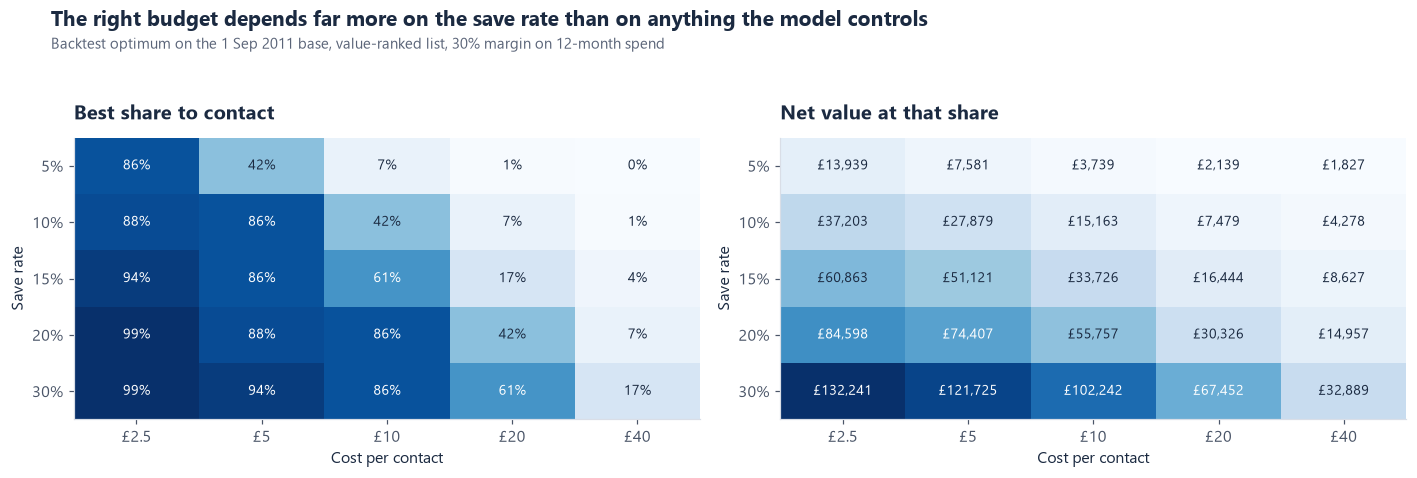

,best_share,net_value
margin,,
0.2000,0.1651,"6,515.2904"
0.3000,0.4165,"15,162.7715"
0.4000,0.5534,"27,244.8864"


In [31]:
o_ev = orders_by["Rank by expected margin at risk"]
sens = []
for sv in (0.05, 0.10, 0.15, 0.20, 0.30):
    for cv in (2.5, 5.0, 10.0, 20.0, 40.0):
        c = net_curve(o_ev, y_te, mval, sv, cv)
        sens.append({"save_rate": sv, "cost": cv, "best_share": np.argmax(c) / len(y_te), "net_value": c.max(),
                     "net_if_top_k_fixed": c[k_ev]})
sens = pd.DataFrame(sens)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.4))
for ax, col, fmt, ttl in ((a1, "best_share", "{:.0%}", "Best share to contact"), (a2, "net_value", "£{:,.0f}", "Net value at that share")):
    piv = sens.pivot(index="save_rate", columns="cost", values=col)
    im = ax.imshow(piv.values, cmap="Blues", aspect="auto")
    for i in range(piv.shape[0]):
        for j in range(piv.shape[1]):
            v = piv.values[i, j]
            ax.text(j, i, fmt.format(v), ha="center", va="center", fontsize=9, color="white" if im.norm(v) > 0.5 else PALETTE["ink"])
    ax.set_xticks(range(piv.shape[1]), [f"£{c:g}" for c in piv.columns]); ax.set_yticks(range(piv.shape[0]), [f"{s:.0%}" for s in piv.index])
    ax.set_xlabel("Cost per contact"); ax.set_ylabel("Save rate"); ax.grid(False)
    headline(ax, ttl)
fig.suptitle("The right budget depends far more on the save rate than on anything the model controls", x=0.04, ha="left", fontsize=14,
             fontweight="bold", color=PALETTE["ink"])
fig.text(0.04, 0.9, "Backtest optimum on the 1 Sep 2011 base, value-ranked list, 30% margin on 12-month spend", fontsize=9.5, color="#5A6478")
fig.tight_layout(rect=(0, 0, 1, 0.9))
plt.show()
margin_sens = pd.DataFrame({m: {"best_share": np.argmax(net_curve(np.argsort(-(p_cal * m * value)), y_te, m * value)) / len(y_te),
                                "net_value": net_curve(np.argsort(-(p_cal * m * value)), y_te, m * value).max()} for m in (0.2, 0.3, 0.4)}).T
margin_sens.index.name = "margin"
margin_sens

The save rate and the contact cost decide the budget. At a 5% save rate and £10 per contact, only the top 7% is worth
contacting (net £3.7K). At 20%, the answer is 86% of the base (net £55.8K). Margin matters too: at 20% the best share is
17%, at 40% it is 55%. A budget cannot be set responsibly until the save rate is measured.

**The test that would prove causal value.** The save rate drives everything above, and it can only be measured by
randomising. Hold out a random share of the targeted list, compare 90-day churn between contacted and held-out
customers. Sample size for a two-sided test at 5% significance and 80% power:

In [32]:
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize
targeted_rate = float(y_te[o_ev[:k_ev]].mean())
power_rows = []
for save in (0.05, 0.10, 0.15, 0.20):
    p1 = targeted_rate * (1 - save)
    n = NormalIndPower().solve_power(proportion_effectsize(targeted_rate, p1), alpha=0.05, power=0.8, ratio=1.0)
    power_rows.append({"true_save_rate": save, "churn_holdout": targeted_rate, "churn_contacted": p1, "customers_per_arm": int(np.ceil(n))})
power = pd.DataFrame(power_rows).set_index("true_save_rate")
print(f"Churn among the value-ranked top {k_ev / len(y_te):.0%} in the backtest: {targeted_rate:.1%}; list size {k_ev:,}")
power

Churn among the value-ranked top 42% in the backtest: 43.1%; list size 1,801


,churn_holdout,churn_contacted,customers_per_arm
true_save_rate,,,
0.0500,0.4314,0.4099,8220
0.1000,0.4314,0.3883,2039
0.1500,0.4314,0.3667,898
0.2000,0.4314,0.3451,500


Detecting a 10% save rate (43.1% churn falling to 38.8%) with 80% power needs about 2,040 customers per arm. One
quarter's value-ranked list holds 1,801 customers, so a 50/50 split of a single quarter can only detect save rates of about
15% or more. Pool two quarters (keeping a 20% hold-out each time), or accept the larger minimum detectable effect.

## 11. Monitoring plan

| What | How | Threshold | Action |
|---|---|---|---|
| Feature drift | PSI of each feature vs the training snapshots, at every scoring run | PSI > 0.10 watch, > 0.25 investigate | Check the source data, then refit |
| Score drift | PSI of the score distribution vs the previous quarter | PSI > 0.25 | Review before the campaign goes out |
| Calibration | Mean predicted vs observed 90-day churn, once labels mature | Ratio outside 0.9-1.1 | Re-estimate the seasonal intercept |
| Discrimination | AUC and top-decile churn on the matured snapshot | AUC < 0.72 (lower bound of today's 95% CI) | Refit on the latest two snapshots |
| Business value | Churn in contacted vs random hold-out (keep 10-20% of the list un-contacted) | Save rate CI excludes the planning value | Re-plan the budget |

Retraining cadence: quarterly, adding the newest matured snapshot. Calibrate every scoring run with that season's
intercept from the previous year.

## Limitations

* **Tenure is left-censored.** It is measured from the first order in the data (Dec 2009), which is why it drifts (PSI
  0.72). Capping it at 365 days removes the artefact (+0.001 validation AUC, +0.003 test); do it in the next release.
* **"Churn" is 90 days without an order, not a closed account.** Many churners come back: reactivations drive most of
  the base's growth (notebook 01). A save is worth less than the budget assumes when the customer would have returned
  anyway, which is one more reason to measure the save rate in a test rather than assume it.
* **One year of seasons.** The seasonal calibration rests on a single prior-year ratio (Sep vs Jun 2010). It worked here
  (estimate 52.5% vs actual 50.5%), but one season is thin evidence; track it every quarter.
* **The budget is a backtest, not a causal estimate.** Margin, save rate and cost are assumptions, varied in section 10;
  only a randomised hold-out turns them into measurements.
* **Coverage and fairness.** Account customers only (about 85% of sales). The model uses no personal attributes beyond
  country, and it ranks customers outside the UK as well as UK customers (AUC 0.78 vs 0.76).

## What I would do next

1. Run the randomised hold-out on the value-ranked list (two quarters to detect a 10% save rate at 80% power).
2. Shadow-score the logistic challenger for one quarter, then promote it if calibration and segment AUC hold.
3. Cap tenure; add monthly snapshots so the model sees every season, with the month as a feature, instead of
   correcting the level afterwards.
4. Replace trailing spend with a forecast of next-year margin (e.g. a BG/NBD + Gamma-Gamma model), so value at risk
   uses the value that is actually at stake.

In [33]:
ci = lambda name: [float(x) for x in mt.loc[name, "AUC 95% CI"].split(" - ")]
report.update_metrics(METRICS, "02_churn_model", {
    "parity": {k: {"published": float(v["published"]), "reproduced": float(v["reproduced"])} for k, v in parity.iterrows()},
    "test_auc": {name: {"auc": float(mt.loc[name, "AUC"]), "ci": ci(name)} for name in mt.index},
    "cv_auc_mean": {name: float(v) for name, v in cvt["roc_auc_mean"].items()},
    "random_cv_auc": float(cv_random), "grouped_cv_auc": float(cv_group),
    "challenger_vs_champion": tests.loc[f"{CL} vs {CH}"].to_dict(),
    "logistic_vs_champion": tests.loc[f"{LOGIT} vs {CH}"].to_dict(),
    "challenger_vs_logistic": tests.loc[f"{CL} vs {LOGIT}"].to_dict(),
    "champion_vs_rfm": tests.loc[f"{CH} vs RFM rule"].to_dict(),
    "champion_vs_recency": tests.loc[f"{CH} vs Recency only"].to_dict(),
    "calibration": {"mean_pred_raw": float(p_champ.mean()), "seasonal_target": float(target_rate), "observed": float(y_te.mean()),
                    "brier_raw": float(cal.loc["Raw champion", "brier"]), "brier_shift": float(cal.loc["Seasonal intercept shift", "brier"])},
    "same_season_feature": {"valid_auc": float(v_seas), "test_auc": float(roc_auc_score(y_te, p_seas)), **season_test},
    "budget": {"assumptions": {"margin": MARGIN, "save_rate": SAVE, "cost_gbp": COST},
               "best_share_value_ranked": k_ev / len(y_te), "net_gbp_value_ranked": best["Rank by expected margin at risk"][1],
               "best_share_risk_ranked": best["Rank by churn probability"][0] / len(y_te), "net_gbp_risk_ranked": best["Rank by churn probability"][1],
               "net_band_90": [float(band[0][k_ev]), float(band[1][k_ev])]},
    "ab_customers_per_arm_at_10pct_save": int(power.loc[0.10, "customers_per_arm"]),
})
print(f"metrics written; notebook runtime {time.perf_counter() - T0:.0f}s")

metrics written; notebook runtime 128s
